================================================================
  CONDITIONAL GAN (cGAN) Tutorial — PyTorch
  Task : Generate MNIST digits 0-9 using a label
================================================================


In [1]:
"""
================================================================
  CONDITIONAL GAN (cGAN) Tutorial — PyTorch
  Task : Generate MNIST digits 0-9 ON DEMAND using a label
================================================================

WHAT IS A CONDITIONAL GAN?
  A regular GAN generates random images — you can't control WHAT
  it generates. A Conditional GAN (cGAN) lets you say:
  "Give me a '7'" and it generates a 7.

  How? Both the Generator and Discriminator receive the class
  label as extra information (a condition).

KEY IDEA:
  Regular GAN:   G(z)        → fake image
  Conditional:   G(z, label) → fake image of class 'label'

  Regular GAN:   D(image)        → real or fake?
  Conditional:   D(image, label) → real or fake for this label?

ARCHITECTURE:
  ┌─────────────────────────────────────────────┐
  │  noise z (100,) + label embedding (10,)     │
  │                    ↓                        │
  │         Generator (4 Linear layers)         │
  │                    ↓                        │
  │        Fake image  28×28 = 784 pixels       │
  └─────────────────────────────────────────────┘

  ┌─────────────────────────────────────────────┐
  │  image (784,) + label embedding (10,)       │
  │                    ↓                        │
  │       Discriminator (3 Linear layers)       │
  │                    ↓                        │
  │        Probability: real(1) or fake(0)      │
  └─────────────────────────────────────────────┘
"""

'\n================================================================\n  CONDITIONAL GAN (cGAN) Tutorial — PyTorch\n  Task : Generate MNIST digits 0-9 ON DEMAND using a label\n================================================================\n\nWHAT IS A CONDITIONAL GAN?\n  A regular GAN generates random images — you can\'t control WHAT\n  it generates. A Conditional GAN (cGAN) lets you say:\n  "Give me a \'7\'" and it generates a 7.\n\n  How? Both the Generator and Discriminator receive the class\n  label as extra information (a condition).\n\nKEY IDEA:\n  Regular GAN:   G(z)        → fake image\n  Conditional:   G(z, label) → fake image of class \'label\'\n\n  Regular GAN:   D(image)        → real or fake?\n  Conditional:   D(image, label) → real or fake for this label?\n\nARCHITECTURE:\n  ┌─────────────────────────────────────────────┐\n  │  noise z (100,) + label embedding (10,)     │\n  │                    ↓                        │\n  │         Generator (4 Linear layers)         │

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid
import os
import numpy as np

In [3]:
# ──────────────────────────────────────────────
# STEP 1 — CONFIGURATION
# All settings in one place. Easy to change.
# ──────────────────────────────────────────────

CONFIG = {
    # Training
    "epochs"      : 50,
    "batch_size"  : 128,
    "lr"          : 2e-4,         # learning rate for both G and D
    "beta1"       : 0.5,          # Adam momentum (lower = more stable for GANs)
    "beta2"       : 0.999,

    # Model sizes
    "noise_dim"   : 100,          # length of the random noise vector
    "embed_dim"   : 10,           # size of label embedding
    "num_classes" : 10,           # MNIST has digits 0-9
    "img_size"    : 28 * 28,      # 784 pixels per image (28×28 flattened)

    # Output
    "save_every"  : 5,            # save sample images every N epochs
    "output_dir"  : "./output/cgan_samples",
    "checkpoint_dir": "./output/cgan_checkpoints",
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using: {device}")


Using: cpu


In [4]:
# ──────────────────────────────────────────────
# STEP 2 — DATASET
# We use PyTorch's built-in MNIST dataset.
# No custom code needed!
# ──────────────────────────────────────────────

def get_dataloader(batch_size):
    """
    Download and load MNIST automatically.
    Images are normalized to [-1, 1] to match Generator's Tanh output.
    """
    transform = transforms.Compose([
        transforms.ToTensor(),                    # PIL image → tensor [0,1]
        transforms.Normalize([0.5], [0.5]),       # shift to [-1, 1]
    ])

    dataset = datasets.MNIST(
        root="./data",
        train=True,
        download=True,      # ← downloads automatically if not found
        transform=transform,
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2,

    )

    print(f"Dataset: {len(dataset):,} training images | "
          f"{len(loader)} batches per epoch")
    return loader



In [5]:

# ──────────────────────────────────────────────
# STEP 3 — GENERATOR
# Takes random noise + label → generates an image
# ──────────────────────────────────────────────

class Generator(nn.Module):
    """
    Input  : [noise (100,)] + [label embedding (10,)] = 110 values
    Output : [flat image (784,)] → reshape to (1, 28, 28)

    Layers: Linear → BatchNorm → LeakyReLU (repeat)
            Final layer uses Tanh to keep pixels in [-1, 1]

    WHY BATCHNORM?
      Stabilises training. Without it, GANs are notoriously unstable.

    WHY LEAKYRELU (not ReLU)?
      LeakyReLU(0.2) lets a small gradient flow even for negative values.
      This prevents "dead neurons" which kill GAN training.
    """

    def __init__(self, noise_dim, embed_dim, num_classes, img_size):
        super().__init__()

        # Label embedding: turns an integer class (e.g. 7) into a
        # learnable vector of size embed_dim.
        # nn.Embedding(10, 10) maps digit 0-9 → 10-dim vector
        self.label_embed = nn.Embedding(num_classes, embed_dim)

        input_dim = noise_dim + embed_dim   # 100 + 10 = 110

        self.net = nn.Sequential(
            # Layer 1: 110 → 256
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2, inplace=True),   #LeakyReLU allows a small gradient (0.2x) for negative inputs to
            # prevent dead neurons, and inplace=True updates the tensor in memory to save computation.

            # Layer 2: 256 → 512
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 3: 512 → 1024
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.2, inplace=True),

            # Output: 1024 → 784 pixels
            nn.Linear(1024, img_size),
            nn.Tanh(),     # ← output in [-1,1] (matches our normalised data)
        )

    def forward(self, noise, labels):
        # labels shape: (batch,)  e.g. [3, 7, 0, 2, ...]
        label_vec = self.label_embed(labels)         # (batch, embed_dim)

        # Concatenate noise and label embedding
        x = torch.cat([noise, label_vec], dim=1)     # (batch, 110)

        img_flat = self.net(x)                       # (batch, 784)
        img = img_flat.view(-1, 1, 28, 28)           # (batch, 1, 28, 28)
        return img



In [6]:
# ──────────────────────────────────────────────
# STEP 4 — DISCRIMINATOR
# Takes an image + label → says REAL or FAKE
# ──────────────────────────────────────────────

class Discriminator(nn.Module):
    """
    Input  : [flat image (784,)] + [label embedding (10,)] = 794 values
    Output : single value (probability of being real)

    NOTE: No BatchNorm in Discriminator (causes instability in D).
    We use Dropout(0.3) instead for regularisation.
    """

    def __init__(self, embed_dim, num_classes, img_size):
        super().__init__()

        self.label_embed = nn.Embedding(num_classes, embed_dim) # convert label into a learnable vector representation so the model can use label information numerically

        input_dim = img_size + embed_dim   # 784 + 10 = 794

        self.net = nn.Sequential(
            # Layer 1: 794 → 1024
            nn.Linear(input_dim, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # Layer 2: 1024 → 512
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # Layer 3: 512 → 256
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # Output: single logit (use BCEWithLogitsLoss, no sigmoid here)
            nn.Linear(256, 1),
        )

    def forward(self, images, labels):
        # Flatten image from (batch, 1, 28, 28) → (batch, 784)
        img_flat = images.view(images.size(0), -1)

        label_vec = self.label_embed(labels)                     # (batch, embed_dim)
        x = torch.cat([img_flat, label_vec], dim=1)              # (batch, 794)
        return self.net(x)                                        # (batch, 1)



In [7]:
# ──────────────────────────────────────────────
# STEP 5 — WEIGHT INITIALISATION
# Good starting weights = faster, more stable training
# ──────────────────────────────────────────────

def init_weights(model):
    """
    Initialise all Conv and Linear weights from N(0, 0.02).
    This is the standard initialisation used in DCGAN paper.
    """
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

# all Linear and Embedding layer weights with small random values from a normal distribution (mean 0, std 0.02) to make GAN training stable

In [8]:
# ──────────────────────────────────────────────
# STEP 6 — TRAINING
# ──────────────────────────────────────────────

def train():
    """
    Main training loop.

    Each epoch, for each batch:
      1. Train Discriminator:
         - Show it real images with correct labels → should output 1
         - Show it fake images with random labels  → should output 0
      2. Train Generator:
         - Generate fake images with random labels
         - Try to fool Discriminator → wants output to be 1
    """

    os.makedirs(CONFIG["output_dir"],     exist_ok=True)
    os.makedirs(CONFIG["checkpoint_dir"], exist_ok=True)

    # ── Data ──
    loader = get_dataloader(CONFIG["batch_size"])

    # ── Models ──
    G = Generator(
        noise_dim   = CONFIG["noise_dim"],
        embed_dim   = CONFIG["embed_dim"],
        num_classes = CONFIG["num_classes"],
        img_size    = CONFIG["img_size"],
    ).to(device)

    D = Discriminator(
        embed_dim   = CONFIG["embed_dim"],
        num_classes = CONFIG["num_classes"],
        img_size    = CONFIG["img_size"],
    ).to(device)

    init_weights(G)
    init_weights(D)

    print(f"Generator params:     {sum(p.numel() for p in G.parameters()):,}")
    print(f"Discriminator params: {sum(p.numel() for p in D.parameters()):,}")

    # ── Loss & Optimisers ──
    criterion = nn.BCEWithLogitsLoss()   # numerically stable sigmoid + BCE

    opt_G = optim.Adam(G.parameters(), lr=CONFIG["lr"],
                       betas=(CONFIG["beta1"], CONFIG["beta2"]))
    opt_D = optim.Adam(D.parameters(), lr=CONFIG["lr"],
                       betas=(CONFIG["beta1"], CONFIG["beta2"]))

    # Fixed noise for visualising progress (same noise each epoch)
    # We'll generate 10 images per digit → 100 total
    fixed_noise  = torch.randn(100, CONFIG["noise_dim"], device=device)
    fixed_labels = torch.tensor(
        [d for d in range(10) for _ in range(10)],   # [0,0,...,1,1,...,9,9,...]
        device=device
    )

    # ── Training loop ──
    for epoch in range(1, CONFIG["epochs"] + 1):
        G.train()
        D.train()

        total_loss_D = 0.0
        total_loss_G = 0.0

        for real_imgs, real_labels in loader:
            real_imgs   = real_imgs.to(device)
            real_labels = real_labels.to(device)
            batch_size  = real_imgs.size(0)

            # ────────────────────────────────────────
            # DISCRIMINATOR UPDATE
            # Goal: correctly classify real AND fake
            # ────────────────────────────────────────
            opt_D.zero_grad()

            # --- Real images ---
            # D sees (real_image, correct_label) → should predict 1
            pred_real = D(real_imgs, real_labels)
            label_real = torch.ones_like(pred_real)        # all-1 targets
            loss_D_real = criterion(pred_real, label_real)

            # --- Fake images ---
            # Sample random noise and random labels
            noise        = torch.randn(batch_size, CONFIG["noise_dim"], device=device)
            fake_labels  = torch.randint(0, CONFIG["num_classes"],
                                         (batch_size,), device=device)
            fake_imgs    = G(noise, fake_labels)           # generate fakes

            # D sees (fake_image, fake_label) → should predict 0
            # .detach() is CRITICAL: stops gradients flowing into G during D update
            pred_fake = D(fake_imgs.detach(), fake_labels)
            label_fake = torch.zeros_like(pred_fake)       # all-0 targets
            loss_D_fake = criterion(pred_fake, label_fake)

            # Average the two losses
            loss_D = (loss_D_real + loss_D_fake) / 2
            loss_D.backward()
            opt_D.step()

            # ────────────────────────────────────────
            # GENERATOR UPDATE
            # Goal: fool the Discriminator
            # ────────────────────────────────────────
            opt_G.zero_grad()

            # Generate new fakes (can reuse fake_imgs but fresh is cleaner)
            noise       = torch.randn(batch_size, CONFIG["noise_dim"], device=device)
            fake_labels = torch.randint(0, CONFIG["num_classes"],
                                        (batch_size,), device=device)
            fake_imgs   = G(noise, fake_labels)

            # Generator WANTS D to say these are real (label = 1)
            pred_for_G  = D(fake_imgs, fake_labels)
            label_real_for_G = torch.ones_like(pred_for_G)
            loss_G = criterion(pred_for_G, label_real_for_G)

            loss_G.backward()
            opt_G.step()

            total_loss_D += loss_D.item()
            total_loss_G += loss_G.item()

        avg_D = total_loss_D / len(loader)
        avg_G = total_loss_G / len(loader)
        print(f"Epoch [{epoch:3d}/{CONFIG['epochs']}]  "
              f"Loss D: {avg_D:.4f}  Loss G: {avg_G:.4f}")

        # Save sample images
        if epoch % CONFIG["save_every"] == 0:
            G.eval()
            with torch.no_grad():
                fake_samples = G(fixed_noise, fixed_labels)

            # Unnormalise [-1,1] → [0,1]
            fake_samples = (fake_samples * 0.5 + 0.5).clamp(0, 1)
            save_image(
                fake_samples,
                os.path.join(CONFIG["output_dir"], f"epoch_{epoch:04d}.png"),
                nrow=10,   # 10 columns = one per digit class
            )

            # Save model checkpoints
            torch.save(G.state_dict(),
                       os.path.join(CONFIG["checkpoint_dir"], f"G_{epoch}.pth"))
            torch.save(D.state_dict(),
                       os.path.join(CONFIG["checkpoint_dir"], f"D_{epoch}.pth"))
            print(f"  → Saved samples + checkpoints (epoch {epoch})")

    print("\nTraining complete!")
    return G, D

In [9]:
# ──────────────────────────────────────────────
# STEP 7 — INFERENCE
# Generate specific digits on demand
# ──────────────────────────────────────────────

def generate_digit(generator_path, digit, n=10, output_path="generated.png"):
    """
    Load a trained generator and produce N images of a specific digit.

    Args:
        generator_path : path to saved G_*.pth checkpoint
        digit          : integer 0-9
        n              : number of images to generate
        output_path    : where to save the grid
    """
    G = Generator(
        noise_dim   = CONFIG["noise_dim"],
        embed_dim   = CONFIG["embed_dim"],
        num_classes = CONFIG["num_classes"],
        img_size    = CONFIG["img_size"],
    ).to(device)

    G.load_state_dict(torch.load(generator_path, map_location=device))
    G.eval()

    noise  = torch.randn(n, CONFIG["noise_dim"], device=device)
    labels = torch.full((n,), digit, dtype=torch.long, device=device)

    with torch.no_grad():
        imgs = G(noise, labels)

    imgs = (imgs * 0.5 + 0.5).clamp(0, 1) # converts image values from [-1, 1] to [0, 1]
    save_image(imgs, output_path, nrow=n)
    print(f"Generated {n} images of digit '{digit}' → {output_path}")


In [10]:

# ──────────────────────────────────────────────
# ENTRY POINT
# ──────────────────────────────────────────────

if __name__ == "__main__":
    G, D = train()

    # Quick demo: generate all 10 digits
    print("\nGenerating samples for all digits...")
    for digit in range(10):
        generate_digit(
            generator_path=f"./output/cgan_checkpoints/G_{CONFIG['epochs']}.pth",
            digit=digit,
            n=8,
            output_path=f"./output/digit_{digit}.png"
        )

Dataset: 60,000 training images | 469 batches per epoch
Generator params:     1,492,596
Discriminator params: 1,470,565
Epoch [  1/50]  Loss D: 0.6513  Loss G: 0.8832
Epoch [  2/50]  Loss D: 0.6151  Loss G: 1.0445
Epoch [  3/50]  Loss D: 0.5865  Loss G: 1.1205
Epoch [  4/50]  Loss D: 0.5841  Loss G: 1.0805
Epoch [  5/50]  Loss D: 0.5957  Loss G: 1.0330
  → Saved samples + checkpoints (epoch 5)
Epoch [  6/50]  Loss D: 0.6042  Loss G: 1.0014
Epoch [  7/50]  Loss D: 0.6115  Loss G: 0.9753
Epoch [  8/50]  Loss D: 0.6145  Loss G: 0.9703
Epoch [  9/50]  Loss D: 0.6117  Loss G: 0.9845
Epoch [ 10/50]  Loss D: 0.6081  Loss G: 1.0031
  → Saved samples + checkpoints (epoch 10)
Epoch [ 11/50]  Loss D: 0.6122  Loss G: 0.9843
Epoch [ 12/50]  Loss D: 0.6219  Loss G: 0.9495
Epoch [ 13/50]  Loss D: 0.6267  Loss G: 0.9312
Epoch [ 14/50]  Loss D: 0.6320  Loss G: 0.9126
Epoch [ 15/50]  Loss D: 0.6372  Loss G: 0.8981
  → Saved samples + checkpoints (epoch 15)
Epoch [ 16/50]  Loss D: 0.6446  Loss G: 0.8724


Dataset: 60,000 training images | 469 batches per epoch


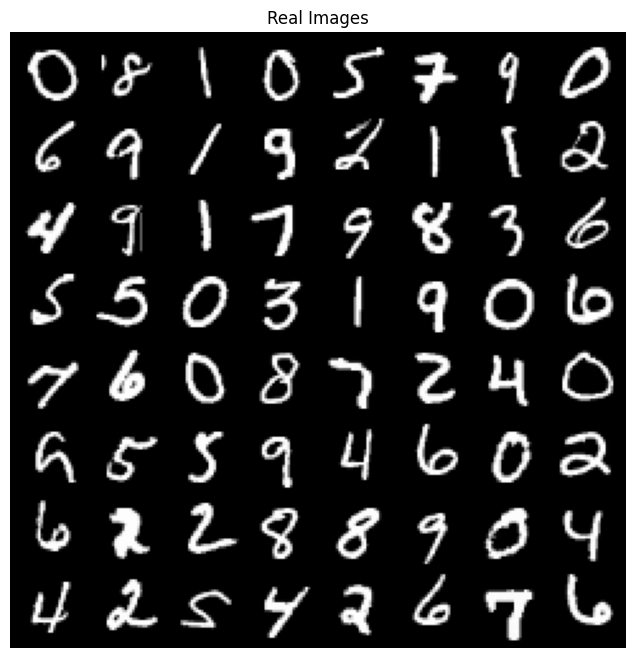

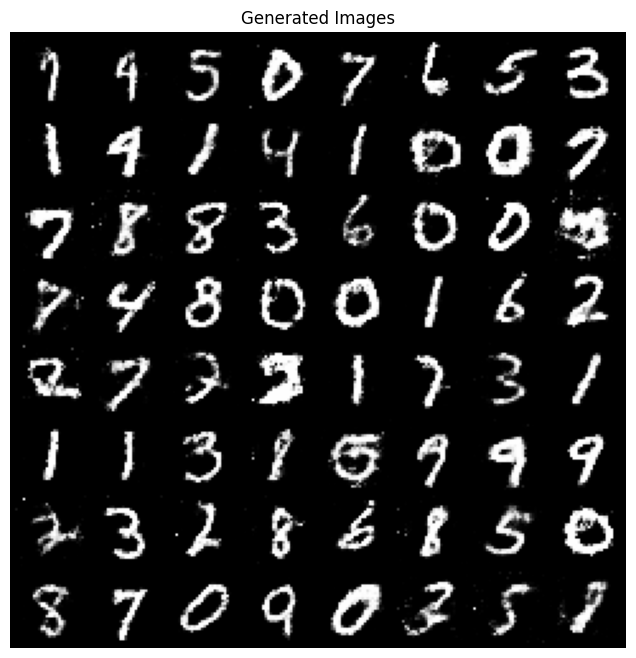

In [11]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

# Get real images from dataloader
real_batch = next(iter(get_dataloader(CONFIG["batch_size"])))
real_images = real_batch[0].to(device)

# Generate fake images using trained Generator G
noise = torch.randn(64, CONFIG["noise_dim"], device=device)

# Random labels for fake images
fake_labels = torch.randint(0, CONFIG["num_classes"], (64,), device=device)

with torch.no_grad():
    fake_images = G(noise, fake_labels)

# Convert [-1,1] → [0,1]
real_images = (real_images * 0.5 + 0.5).clamp(0, 1)
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

# Display real images
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Real Images")
plt.imshow(vutils.make_grid(real_images[:64], nrow=8).permute(1,2,0).cpu())
plt.show()

# Display generated images
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Generated Images")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

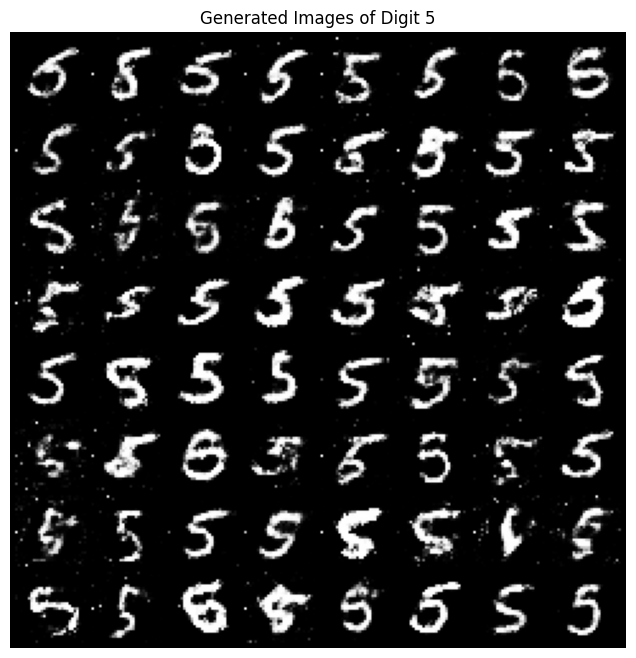

In [13]:
# Generate ONLY one specific digit
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

digit = 5   # Change this to any digit 0–9

noise = torch.randn(64, CONFIG["noise_dim"], device=device)
labels = torch.full((64,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    fake_images = G(noise, labels)

# Convert [-1,1] → [0,1]
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(8,8))
plt.axis("off")
plt.title(f"Generated Images of Digit {digit}")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

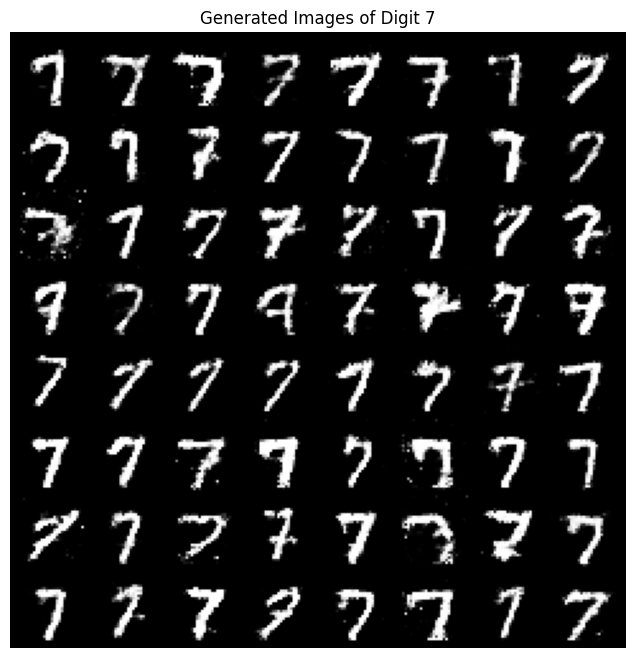

In [14]:
# Generate ONLY one specific digit
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

digit = 7   # Change this to any digit 0–9

noise = torch.randn(64, CONFIG["noise_dim"], device=device)
labels = torch.full((64,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    fake_images = G(noise, labels)

# Convert [-1,1] → [0,1]
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(8,8))
plt.axis("off")
plt.title(f"Generated Images of Digit {digit}")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

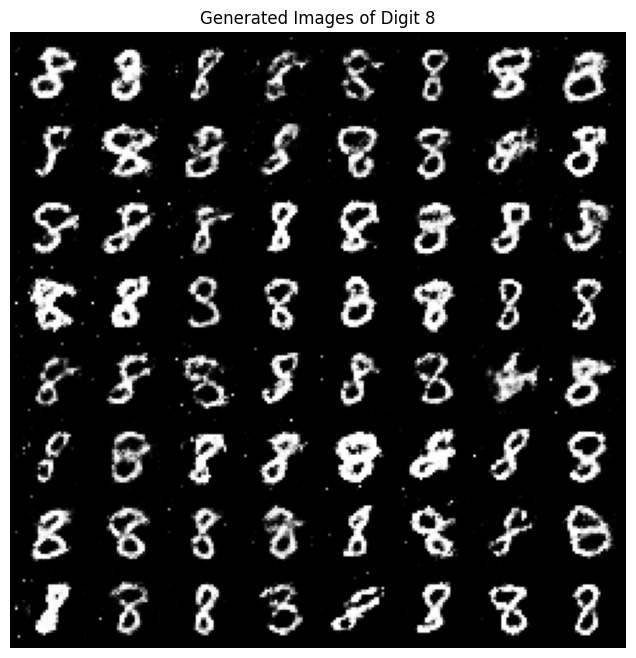

In [15]:
# Generate ONLY one specific digit
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

digit = 8   # Change this to any digit 0–9

noise = torch.randn(64, CONFIG["noise_dim"], device=device)
labels = torch.full((64,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    fake_images = G(noise, labels)

# Convert [-1,1] → [0,1]
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(8,8))
plt.axis("off")
plt.title(f"Generated Images of Digit {digit}")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

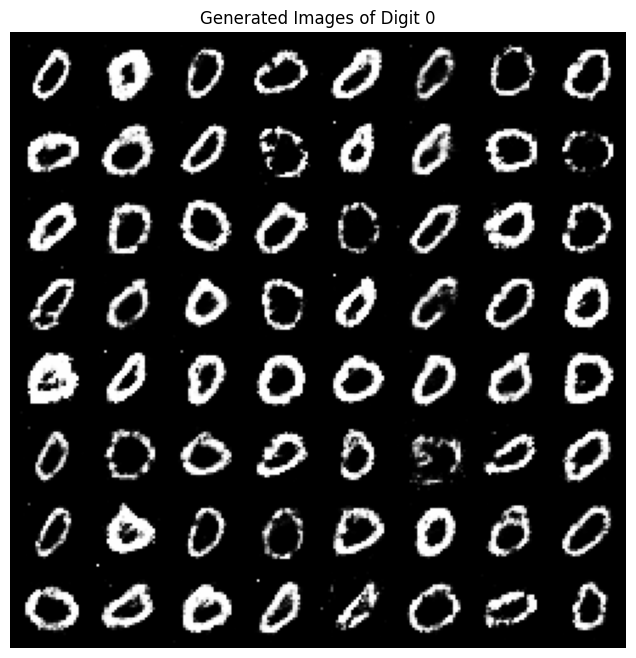

In [16]:
# Generate ONLY one specific digit
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

digit = 0   # Change this to any digit 0–9

noise = torch.randn(64, CONFIG["noise_dim"], device=device)
labels = torch.full((64,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    fake_images = G(noise, labels)

# Convert [-1,1] → [0,1]
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(8,8))
plt.axis("off")
plt.title(f"Generated Images of Digit {digit}")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

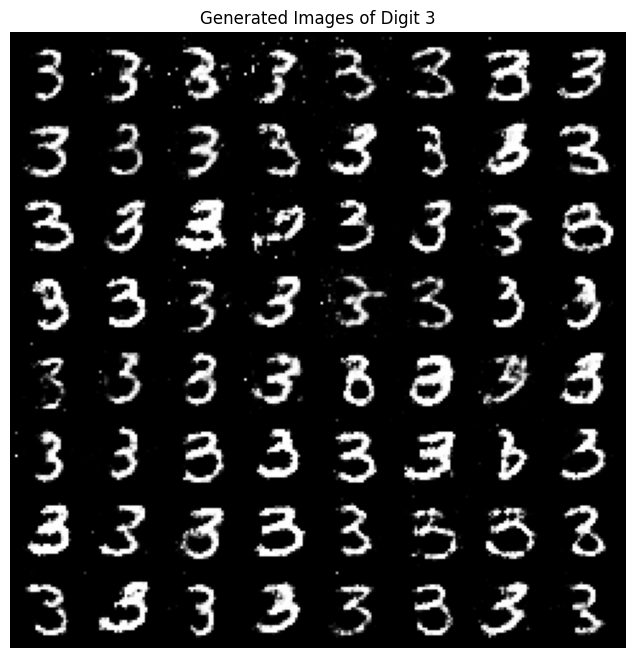

In [17]:
# Generate ONLY one specific digit
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

digit = 3   # Change this to any digit 0–9

noise = torch.randn(64, CONFIG["noise_dim"], device=device)
labels = torch.full((64,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    fake_images = G(noise, labels)

# Convert [-1,1] → [0,1]
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(8,8))
plt.axis("off")
plt.title(f"Generated Images of Digit {digit}")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

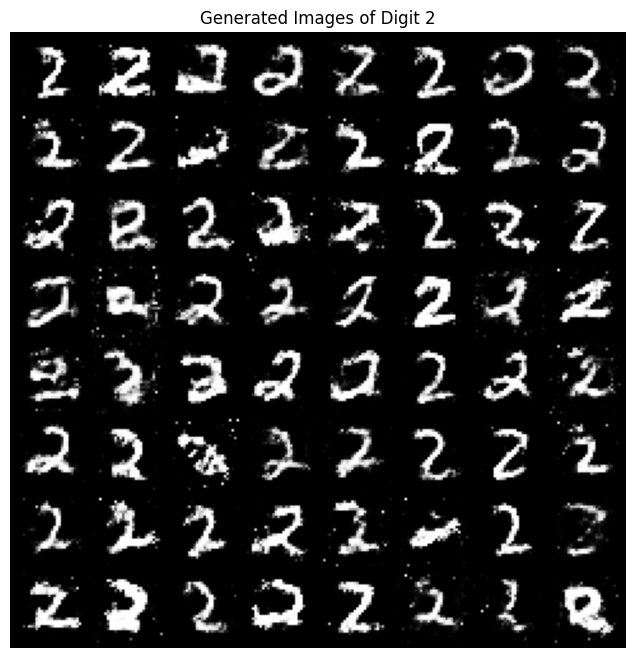

In [18]:
# Generate ONLY one specific digit
import matplotlib.pyplot as plt
import torchvision.utils as vutils
import torch

digit = 2   # Change this to any digit 0–9

noise = torch.randn(64, CONFIG["noise_dim"], device=device)
labels = torch.full((64,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    fake_images = G(noise, labels)

# Convert [-1,1] → [0,1]
fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(8,8))
plt.axis("off")
plt.title(f"Generated Images of Digit {digit}")
plt.imshow(vutils.make_grid(fake_images, nrow=8).permute(1,2,0).cpu())
plt.show()

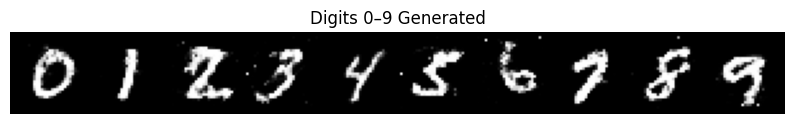

In [19]:
# Show digits 0–9
noise = torch.randn(10, CONFIG["noise_dim"], device=device)
labels = torch.arange(0, 10, device=device)

with torch.no_grad():
    fake_images = G(noise, labels)

fake_images = (fake_images * 0.5 + 0.5).clamp(0, 1)

plt.figure(figsize=(10,2))
plt.axis("off")
plt.title("Digits 0–9 Generated")
plt.imshow(vutils.make_grid(fake_images, nrow=10).permute(1,2,0).cpu())
plt.show()